In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path(
    r"data/题5_共享单车骑行_202401.csv"
)
# 编号是标识符，按字符串读取，避免被当成可计算数值。
df_raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    dtype={"ride_id": "string", "start_station_id": "string", "end_station_id": "string"},
)
print("原始数据行列数：", df_raw.shape)
print(df_raw.head(3).to_string(index=False))


原始数据行列数： (238834, 13)
         ride_id rideable_type          started_at            ended_at start_station_name start_station_id    end_station_name end_station_id  start_lat  start_lng   end_lat    end_lng member_casual
748A93D7DE8A41CD  classic_bike 2024-01-25 15:49:59 2024-01-25 15:52:35      1st & O St NW            31519       1st & L St NW          31677  38.908643 -77.012365 38.903819 -77.011987        member
75CBFD136F06305B  classic_bike 2024-01-02 16:44:58 2024-01-02 16:53:25      1st & O St NW            31519 4th & College St NW          31138  38.908643 -77.012365 38.921233 -77.018135        member
0536C9720F87E04C  classic_bike 2024-01-24 15:40:15 2024-01-24 15:43:55      1st & O St NW            31519       1st & L St NW          31677  38.908643 -77.012365 38.903819 -77.011987        member


In [10]:
# 每列的数据类型、缺失数量、缺失比例
quality = pd.DataFrame({
    "数据类型": df_raw.dtypes.astype(str),
    "缺失数量": df_raw.isna().sum(),
    "缺失比例(%)": (df_raw.isna().mean() * 100).round(2)
}).sort_values("缺失数量", ascending=False)

display(quality)

# 检查重复
print("完全重复的行数：", df_raw.duplicated().sum())
print("重复的订单编号数：", df_raw["ride_id"].duplicated().sum())

,数据类型,缺失数量,缺失比例(%)
end_station_name,str,39741,16.64
end_station_id,string,39741,16.64
start_station_id,string,37220,15.58
start_station_name,str,37220,15.58
end_lat,float64,203,0.08
end_lng,float64,203,0.08
started_at,str,0,0.00
rideable_type,str,0,0.00
ride_id,string,0,0.00
ended_at,str,0,0.00


完全重复的行数： 0
重复的订单编号数： 0


缺失主要集中在站点信息，暂时保留这些订单。
起点和终点缺失可能出现在同一笔订单中，所以缺失数量不能直接相加。
started_at 和 ended_at 虽然没有缺失，但目前是 str（文本），需要转换成时间类型才能计算时长。

In [11]:
# 保留原始数据，后续处理使用 df
df = df_raw.copy()

# 1. 将文本转换为时间
for col in ["started_at", "ended_at"]:
    df[col] = pd.to_datetime(
        df[col],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

# 2. 计算骑行时长，单位为分钟
df["duration_min"] = (
    df["ended_at"] - df["started_at"]
).dt.total_seconds() / 60

# 3. 检查转换后是否出现无法识别的时间
print("时间转换失败的数量：")
print(df[["started_at", "ended_at"]].isna().sum())

# 4. 查看计算结果
display(df[["started_at", "ended_at", "duration_min"]].head())

# 5. 查看时长分布
print("骑行时长统计（分钟）：")
print(df["duration_min"].describe(percentiles=[0.01, 0.5, 0.95, 0.99]))

print("负时长数量：", (df["duration_min"] < 0).sum())
print("零时长数量：", (df["duration_min"] == 0).sum())

时间转换失败的数量：
started_at    0
ended_at      0
dtype: int64


,started_at,ended_at,duration_min
0,2024-01-25 15:49:59,2024-01-25 15:52:35,2.600000
1,2024-01-02 16:44:58,2024-01-02 16:53:25,8.450000
2,2024-01-24 15:40:15,2024-01-24 15:43:55,3.666667
3,2024-01-04 15:35:00,2024-01-04 15:37:35,2.583333
4,2024-01-05 12:27:58,2024-01-05 12:35:40,7.700000


骑行时长统计（分钟）：
count    238834.000000
mean         14.770581
std          56.395047
min          -4.283333
1%            0.366667
50%           8.750000
95%          34.255833
99%          81.866667
max        1499.950000
Name: duration_min, dtype: float64
负时长数量： 44
零时长数量： 91


中位数是 8.75 分钟，一半订单的时长不超过这个值。
平均值约 14.77 分钟，高于中位数，说明长时长记录拉高了平均值。
最长约 25 小时，需要进一步检查。
44 条负时长、91 条零时长，可以先从有效骑行分析中排除。负时长不要取绝对值，那会掩盖时间错误。

In [12]:
import numpy as np

# 1. 保存时间无效或时长不大于 0 的记录，便于追溯
bad_time = (
    df["duration_min"].isna()
    | (df["duration_min"] <= 0)
)

df_bad_time = df.loc[bad_time].copy()

# 2. 建立有效时长数据集，保留站点缺失的订单
df_valid = df.loc[~bad_time].copy()

print("处理前记录数：", len(df))
print("排除记录数：", len(df_bad_time))
print("剩余记录数：", len(df_valid))

# 3. 将时长分组，暂不删除过短、过长的记录
df_valid["duration_group"] = np.select(
    [
        df_valid["duration_min"] < 1,
        df_valid["duration_min"] <= 180
    ],
    [
        "不足1分钟",
        "1–180分钟"
    ],
    default="超过180分钟"
)

print("\n各时长组的记录数：")
print(
    df_valid["duration_group"]
    .value_counts()
    .reindex(["不足1分钟", "1–180分钟", "超过180分钟"])
)

# 4. 看看最长的 10 笔订单
display(
    df_valid.nlargest(10, "duration_min")[
        [
            "rideable_type",
            "started_at",
            "ended_at",
            "duration_min",
            "member_casual"
        ]
    ]
)

处理前记录数： 238834
排除记录数： 135
剩余记录数： 238699

各时长组的记录数：
duration_group
不足1分钟        4722
1–180分钟    233180
超过180分钟       797
Name: count, dtype: int64


,rideable_type,started_at,ended_at,duration_min,member_casual
5803,classic_bike,2024-01-30 12:59:46,2024-01-31 13:59:43,1499.950000,member
77672,classic_bike,2024-01-03 09:47:23,2024-01-04 10:47:20,1499.950000,member
127558,classic_bike,2024-01-29 19:10:47,2024-01-30 20:10:44,1499.950000,casual
165842,classic_bike,2024-01-29 08:30:46,2024-01-30 09:30:43,1499.950000,member
180879,classic_bike,2024-01-23 22:40:18,2024-01-24 23:40:15,1499.950000,casual
184276,classic_bike,2024-01-05 16:25:26,2024-01-06 17:25:23,1499.950000,casual
1995,classic_bike,2024-01-14 14:59:27,2024-01-15 15:59:23,1499.933333,casual
5787,classic_bike,2024-01-28 11:37:44,2024-01-29 12:37:40,1499.933333,casual
16109,classic_bike,2024-01-22 02:45:45,2024-01-23 03:45:41,1499.933333,member
17226,classic_bike,2024-01-29 10:21:21,2024-01-30 11:21:17,1499.933333,member


筛选影响最大的 5 天：


,all_positive,duration_1_180,excluded_pct
started_at,,,
2024-01-01,4898,4705,3.94
2024-01-02,7806,7577,2.93
2024-01-20,3797,3692,2.77
2024-01-03,9143,8896,2.70
2024-01-29,9625,9368,2.67


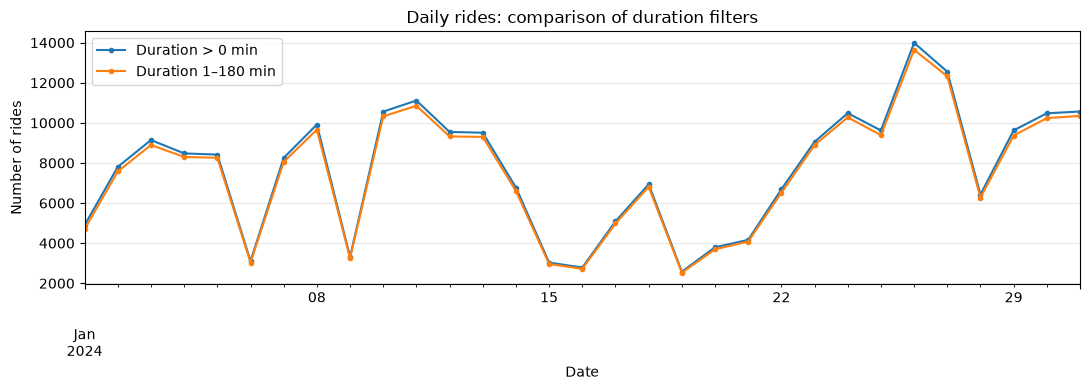

In [13]:
import matplotlib.pyplot as plt

# 1. 建立用于比较的子集，df_valid 继续保留
# 1–180 分钟只是候选筛选范围，不代表范围外全部是错误数据
df_1_180 = df_valid.loc[
    df_valid["duration_min"].between(1, 180)
].copy()

# 2. 分别统计两种口径下的每日出发订单数
daily_all = (
    df_valid.set_index("started_at")
    .resample("D")
    .size()
)

daily_filtered = (
    df_1_180.set_index("started_at")
    .resample("D")
    .size()
)

# 3. 合并，比较每天减少了多少订单
daily_compare = pd.concat(
    [daily_all, daily_filtered],
    axis=1
)
daily_compare.columns = ["all_positive", "duration_1_180"]
daily_compare = daily_compare.fillna(0).astype(int)

daily_compare["excluded_pct"] = (
    (daily_compare["all_positive"]
     - daily_compare["duration_1_180"])
    / daily_compare["all_positive"]
    * 100
).round(2)

print("筛选影响最大的 5 天：")
display(
    daily_compare.sort_values("excluded_pct", ascending=False).head()
)

# 4. 绘制两种口径的每日订单量
ax = daily_compare[["all_positive", "duration_1_180"]].plot(
    figsize=(11, 4),
    marker="o",
    markersize=3
)

ax.set_title("Daily rides: comparison of duration filters")
ax.set_xlabel("Date")
ax.set_ylabel("Number of rides")
ax.legend(["Duration > 0 min", "Duration 1–180 min"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

时长筛选对每日订单总量的影响较小，两种口径下的整体走势接近。为检验时长筛选对分析结果的影响，对比了全部正时长订单与时长为 1–180 分钟的订单。筛选后订单总量减少约 2.31%，单日减少比例最高为 3.94%，每日订单量的整体变化趋势接近，说明日总量规律对该筛选规则较稳健。

day_type,Mon-Fri,Sat-Sun
hour,,
0,58.5,139.4
1,34.1,101.1
2,23.7,62.2
3,10.7,28.0
4,16.4,21.6
5,57.0,20.9
6,181.9,51.8
7,418.0,96.6
8,717.4,211.9


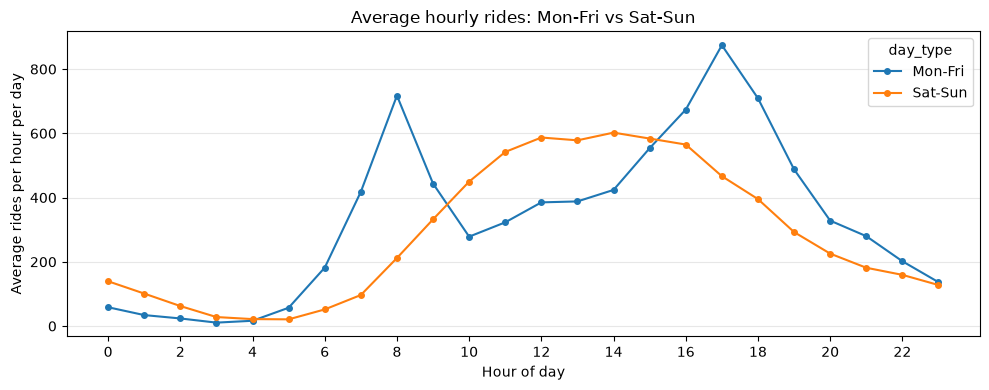

In [21]:
# 1. 按实际日期和小时统计订单数
# 每行代表某一天的某一个小时
hourly_counts = (
    df_valid.set_index("started_at")
    .resample("h")
    .size()
    .rename("rides")
    .to_frame()
)

# 2. 提取小时和日期类型
hourly_counts["hour"] = hourly_counts.index.hour

hourly_counts["day_type"] = np.where(
    hourly_counts.index.dayofweek < 5,
    "Mon-Fri",
    "Sat-Sun"
)

# 3. 计算两类日期在每个小时的平均订单量
hourly_pattern = (
    hourly_counts
    .groupby(["hour", "day_type"])["rides"]
    .mean()
    .unstack("day_type")
    .reindex(range(24))
)

display(hourly_pattern.round(1))

# 4. 画出一天内的需求变化
ax = hourly_pattern[["Mon-Fri", "Sat-Sun"]].plot(
    figsize=(10, 4),
    marker="o",
    markersize=4
)

ax.set_title("Average hourly rides: Mon-Fri vs Sat-Sun")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average rides per hour per day")
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


2024 年 1 月，周一至周五的日内骑行量呈现明显的双峰形态，分别出现在 08:00–09:00 和 17:00–18:00，且晚高峰高于早高峰。周末早间需求较低，主要高需求时段集中在中午至下午。这表明不同日期类型的需求时间分布存在差异，调度时段应分别考虑。

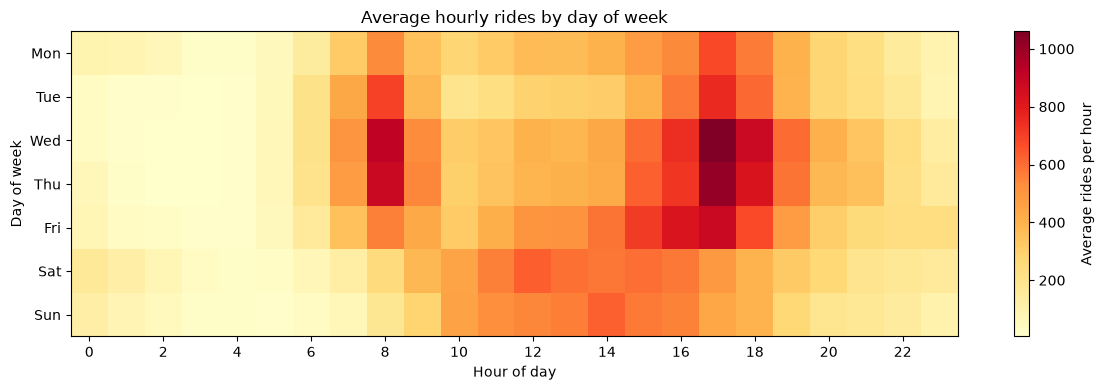

,peak_hour,average_rides
Mon,17,680.8
Tue,17,759.4
Wed,17,1060.6
Thu,17,1015.0
Fri,17,887.0
Sat,12,628.5
Sun,14,625.0


In [22]:
# 1. 提取星期：周一=0，周日=6
hourly_counts["weekday"] = hourly_counts.index.dayofweek

# 2. 每个格子：某个星期、某个小时的平均订单量
weekday_hour = hourly_counts.pivot_table(
    index="weekday",
    columns="hour",
    values="rides",
    aggfunc="mean"
).reindex(
    index=range(7),
    columns=range(24)
)

# 3. 绘制热力图
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(12, 4))

im = ax.imshow(
    weekday_hour.to_numpy(),
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))
ax.set_yticks(range(7))
ax.set_yticklabels(weekday_names)

ax.set_xlabel("Hour of day")
ax.set_ylabel("Day of week")
ax.set_title("Average hourly rides by day of week")

fig.colorbar(im, ax=ax, label="Average rides per hour")
plt.tight_layout()
plt.show()

# 4. 列出每个星期的最高需求小时
peak_summary = pd.DataFrame({
    "peak_hour": weekday_hour.idxmax(axis=1),
    "average_rides": weekday_hour.max(axis=1).round(1)
})

peak_summary.index = weekday_names
display(peak_summary)


本月周一至周五的平均骑行需求均在 17:00–18:00 达到最高值，其中周三和周四的晚高峰较为突出。周末需求主要集中在中午至下午，周六、周日的峰值时段分别为 12:00–13:00 和 14:00–15:00。

rides  median_duration_min  share_of_all_pct
member_casual rideable_type                                              
casual        classic_bike   27126                12.63             11.36
              electric_bike  34612                 9.30              14.5
member        classic_bike   89537                 8.28             37.51
              electric_bike  87424                 8.13             36.63

rideable_type,classic_bike,electric_bike
member_casual,,
casual,43.94,56.06
member,50.60,49.40


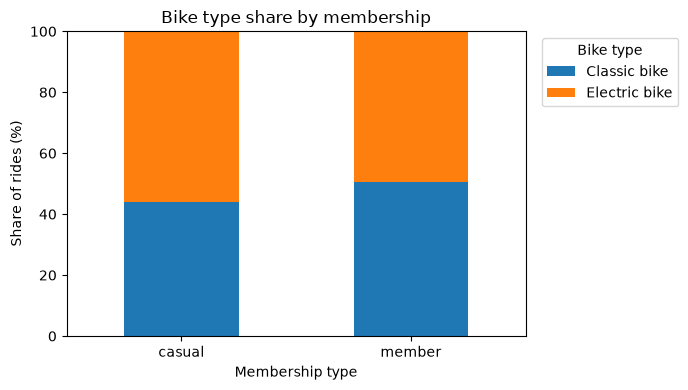

In [23]:
# 1. 按会员类型和车型分组
group_summary = (
    df_valid
    .groupby(["member_casual", "rideable_type"])
    .agg(
        rides=("ride_id", "size"),
        median_duration_min=("duration_min", "median")
    )
)

# 每个组合占全部正时长订单的比例
group_summary["share_of_all_pct"] = (
    group_summary["rides"] / len(df_valid) * 100
)

display(group_summary.round(2))

# 2. 分别计算会员、非会员订单中的车型占比
bike_share = pd.crosstab(
    df_valid["member_casual"],
    df_valid["rideable_type"],
    normalize="index"
) * 100

display(bike_share.round(2))

# 3. 绘制车型占比图
ax = bike_share[["classic_bike", "electric_bike"]].plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4),
    rot=0
)

ax.set_title("Bike type share by membership")
ax.set_xlabel("Membership type")
ax.set_ylabel("Share of rides (%)")
ax.set_ylim(0, 100)
ax.legend(
    ["Classic bike", "Electric bike"],
    title="Bike type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

在本月正时长订单中，会员订单占主要部分。非会员订单的电助力车占比高于会员订单，且在两种车型下，非会员的骑行时长中位数均高于会员。这表明两类订单在车型构成和骑行时长上存在差异，具体原因仍需结合行程、价格和车辆供给等信息分析。

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 如果你之前修改过文件路径，这里沿用之前能成功读取的路径
file_path = r"data/题5_共享单车骑行_202401.csv"

df_raw = pd.read_csv(
    file_path,
    dtype={
        "ride_id": "string",
        "start_station_id": "string",
        "end_station_id": "string"
    }
)

df = df_raw.copy()

# 转换时间
for col in ["started_at", "ended_at"]:
    df[col] = pd.to_datetime(
        df[col],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

# 计算时长
df["duration_min"] = (
    df["ended_at"] - df["started_at"]
).dt.total_seconds() / 60

# 恢复之前的筛选口径：只排除无效时间、负时长和零时长
bad_time = df["duration_min"].isna() | (df["duration_min"] <= 0)

df_bad_time = df.loc[bad_time].copy()
df_valid = df.loc[~bad_time].copy()

print("df_valid 已恢复，记录数：", len(df_valid))

df_valid 已恢复，记录数： 238699


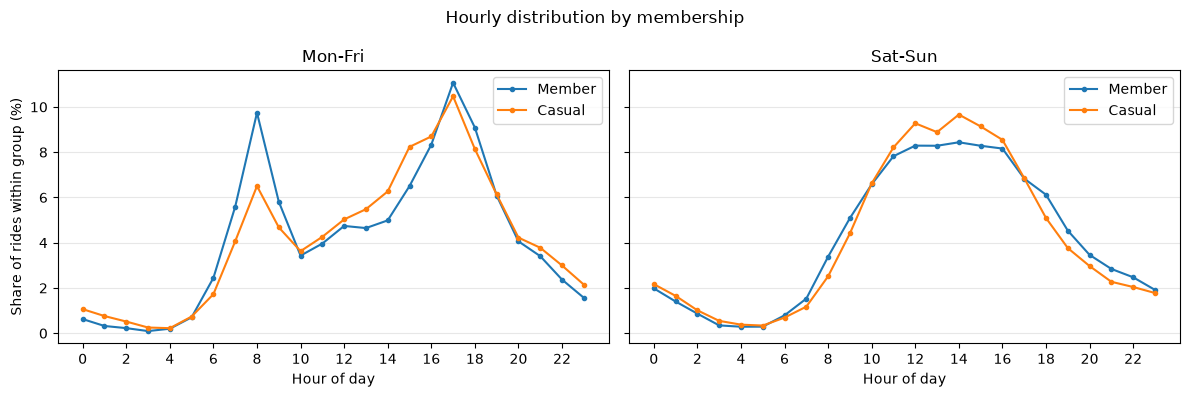

peak_hour  peak_share_pct
day_type member_casual                           
Mon-Fri  casual                17           10.47
         member                17           11.07
Sat-Sun  casual                14            9.66
         member                14            8.44

In [25]:
# 1. 为每笔订单添加小时、日期类型
df_valid["hour"] = df_valid["started_at"].dt.hour

df_valid["day_type"] = np.where(
    df_valid["started_at"].dt.dayofweek < 5,
    "Mon-Fri",
    "Sat-Sun"
)

# 2. 计算各群体内部的小时订单占比
# 每列对应一个“日期类型 × 会员类型”组合
# 每列的 24 个小时占比合计为 100%
member_hour_pct = (
    pd.crosstab(
        index=df_valid["hour"],
        columns=[
            df_valid["day_type"],
            df_valid["member_casual"]
        ],
        normalize="columns"
    )
    .reindex(range(24), fill_value=0)
    * 100
)

# 3. 分别画周一至周五、周末的时间分布
fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharey=True
)

for ax, day_type in zip(axes, ["Mon-Fri", "Sat-Sun"]):
    member_hour_pct[day_type][["member", "casual"]].plot(
        ax=ax,
        marker="o",
        markersize=3
    )

    ax.set_title(day_type)
    ax.set_xlabel("Hour of day")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis="y", alpha=0.3)
    ax.legend(["Member", "Casual"])

axes[0].set_ylabel("Share of rides within group (%)")
fig.suptitle("Hourly distribution by membership")

plt.tight_layout()
plt.show()

# 4. 查看四个群体各自占比最高的小时
member_peak = pd.DataFrame({
    "peak_hour": member_hour_pct.idxmax(),
    "peak_share_pct": member_hour_pct.max().round(2)
})

display(member_peak)


分日期类型比较后，会员与非会员订单的日内峰值时间基本一致，但时间分布的集中程度存在差异。周一至周五，会员订单的早高峰更突出；周末，非会员订单在中午至下午的占比更高。

In [26]:
# 1. 明确统计窗口：2024 年 1 月
month_start = pd.Timestamp("2024-01-01")
month_end = pd.Timestamp("2024-02-01")

departures = df_valid.loc[
    (df_valid["started_at"] >= month_start)
    & (df_valid["started_at"] < month_end)
].copy()

arrivals = df_valid.loc[
    (df_valid["ended_at"] >= month_start)
    & (df_valid["ended_at"] < month_end)
].copy()

# 2. 检查两端站点的可识别比例
print(
    "起点站点可识别比例：",
    f'{departures["start_station_id"].notna().mean():.2%}'
)
print(
    "终点站点可识别比例：",
    f'{arrivals["end_station_id"].notna().mean():.2%}'
)

# 3. 分别统计借出和归还
# groupby 默认不统计缺失的站点编号
out_counts = (
    departures.groupby("start_station_id")
    .size()
    .rename("departures")
)

in_counts = (
    arrivals.groupby("end_station_id")
    .size()
    .rename("arrivals")
)

station_flow = (
    pd.concat([out_counts, in_counts], axis=1)
    .fillna(0)
    .astype(int)
)
station_flow.index.name = "station_id"

# 4. 计算净流出和借还总次数
station_flow["net_outflow"] = (
    station_flow["departures"] - station_flow["arrivals"]
)
station_flow["total_events"] = (
    station_flow["departures"] + station_flow["arrivals"]
)

# 5. 添加展示用站名，统计仍以站点编号为准
start_names = df_valid[
    ["start_station_id", "start_station_name"]
].rename(columns={
    "start_station_id": "station_id",
    "start_station_name": "station_name"
})

end_names = df_valid[
    ["end_station_id", "end_station_name"]
].rename(columns={
    "end_station_id": "station_id",
    "end_station_name": "station_name"
})

station_names = (
    pd.concat([start_names, end_names], ignore_index=True)
    .dropna(subset=["station_id", "station_name"])
    .drop_duplicates("station_id")
    .set_index("station_id")["station_name"]
)

station_flow = station_flow.join(station_names)

# 6. 查看借还最活跃的 10 个站点
display(
    station_flow.nlargest(10, "total_events")[
        ["station_name", "departures", "arrivals",
         "net_outflow", "total_events"]
    ]
)

起点站点可识别比例： 84.45%
终点站点可识别比例： 83.40%


,station_name,departures,arrivals,net_outflow,total_events
station_id,,,,,
31623,Columbus Circle / Union Station,2998,2957,41,5955
31229,New Hampshire Ave & T St NW,2552,2541,11,5093
31201,15th & P St NW,2049,2045,4,4094
31101,14th & V St NW,1932,1893,39,3825
31600,5th & K St NW,1843,1869,-26,3712
31613,Eastern Market Metro / Pennsylvania Ave & 8th ...,1843,1852,-9,3695
31603,1st & M St NE,1749,1751,-2,3500
31627,M St & Delaware Ave NE,1757,1738,19,3495
31200,Massachusetts Ave & Dupont Circle NW,1615,1712,-97,3327


周一至周五的天数： 23


,station_name,am_net_per_day,pm_net_per_day
station_id,,,
31242,18th St & Pennsylvania Ave NW,-13.61,10.78
31101,14th & V St NW,11.91,-9.35
31279,19th & G St NW,-11.09,8.96
31229,New Hampshire Ave & T St NW,11.48,-8.91
31277,17th & G St NW,-16.22,7.83
31125,15th & W St NW,8.83,-7.57
31272,Washington & Independence Ave SW/HHS,-7.43,7.57
31233,17th & K St NW / Farragut Square,-15.17,7.26


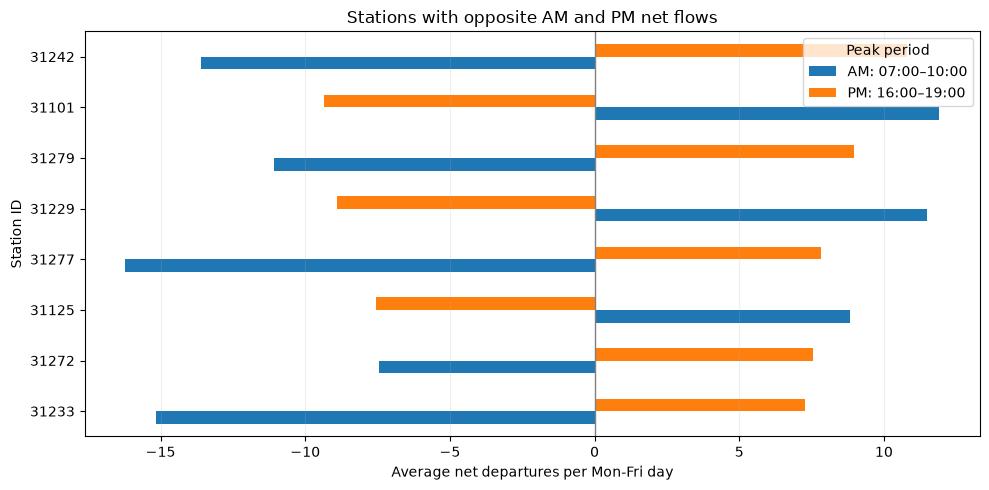

In [27]:
# 1. 计算本月周一至周五的总天数
dates = pd.date_range(
    month_start, month_end,
    freq="D", inclusive="left"
)
n_weekdays = (dates.dayofweek < 5).sum()

print("周一至周五的天数：", n_weekdays)

# 2. 定义函数：统计指定时段的站点流量
def get_peak_flow(start_hour, end_hour):
    # 借出按出发时间判断
    out_mask = (
        (departures["started_at"].dt.dayofweek < 5)
        & (departures["started_at"].dt.hour >= start_hour)
        & (departures["started_at"].dt.hour < end_hour)
    )

    # 归还按到达时间判断
    in_mask = (
        (arrivals["ended_at"].dt.dayofweek < 5)
        & (arrivals["ended_at"].dt.hour >= start_hour)
        & (arrivals["ended_at"].dt.hour < end_hour)
    )

    out_counts = (
        departures.loc[out_mask]
        .groupby("start_station_id").size()
        .rename("out")
    )
    in_counts = (
        arrivals.loc[in_mask]
        .groupby("end_station_id").size()
        .rename("in")
    )

    result = (
        pd.concat([out_counts, in_counts], axis=1)
        .fillna(0)
    )

    result["net_per_day"] = (
        (result["out"] - result["in"]) / n_weekdays
    )
    return result

# 3. 合并早晚高峰结果
am = get_peak_flow(7, 10).add_prefix("am_")
pm = get_peak_flow(16, 19).add_prefix("pm_")

peak_flow = am.join(pm, how="outer").fillna(0)
peak_flow.index.name = "station_id"
peak_flow = peak_flow.join(station_names)

# 4. 筛选早晚净流量方向相反的站点
# 一正一负，相乘就小于 0
tidal_candidates = peak_flow.loc[
    peak_flow["am_net_per_day"]
    * peak_flow["pm_net_per_day"] < 0
].copy()

# 用较弱一侧的净流量绝对值排序，
# 优先查看早晚两侧都有较明显净流量的站点
tidal_candidates["min_abs_net"] = np.minimum(
    tidal_candidates["am_net_per_day"].abs(),
    tidal_candidates["pm_net_per_day"].abs()
)

top_tidal = tidal_candidates.nlargest(8, "min_abs_net")

display(
    top_tidal[
        ["station_name", "am_net_per_day", "pm_net_per_day"]
    ].round(2)
)

# 5. 绘制早晚高峰净流量对比
# 先给数据列设置正确的图例名称
plot_data = top_tidal[
    ["am_net_per_day", "pm_net_per_day"]
].iloc[::-1].rename(columns={
    "am_net_per_day": "AM: 07:00–10:00",
    "pm_net_per_day": "PM: 16:00–19:00"
})

ax = plot_data.plot(
    kind="barh",
    figsize=(10, 5)
)

# 零线不参与图例
ax.axvline(
    0,
    color="gray",
    linewidth=1,
    label="_nolegend_"
)

ax.set_title("Stations with opposite AM and PM net flows")
ax.set_xlabel("Average net departures per Mon-Fri day")
ax.set_ylabel("Station ID")

# 自动使用数据列名，不手动按顺序指定标签
ax.legend(title="Peak period")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

In [28]:
# 1. 准备完整的“日期 × 站点”组合
weekday_dates = dates[dates.dayofweek < 5]
station_ids = top_tidal.index

full_index = pd.MultiIndex.from_product(
    [weekday_dates, station_ids],
    names=["date", "station_id"]
)

# 2. 按日期、站点统计指定时段的事件数量
def get_daily_counts(data, time_col, station_col, start_hour, end_hour):
    mask = (
        (data[time_col].dt.dayofweek < 5)
        & data[time_col].dt.hour.between(
            start_hour, end_hour, inclusive="left"
        )
        & data[station_col].isin(station_ids)
    )

    selected = data.loc[mask, [time_col, station_col]].copy()
    selected["date"] = selected[time_col].dt.normalize()

    return (
        selected.groupby(["date", station_col])
        .size()
        .rename_axis(["date", "station_id"])
        .reindex(full_index, fill_value=0)
    )

# 3. 计算每天早、晚高峰的净流出
am_daily = (
    get_daily_counts(departures, "started_at", "start_station_id", 7, 10)
    - get_daily_counts(arrivals, "ended_at", "end_station_id", 7, 10)
).unstack("station_id")

pm_daily = (
    get_daily_counts(departures, "started_at", "start_station_id", 16, 19)
    - get_daily_counts(arrivals, "ended_at", "end_station_id", 16, 19)
).unstack("station_id")

# 4. 检查每天的方向是否与月平均方向一致
# np.sign：正数变成 1，负数变成 -1，零仍是 0
am_direction = np.sign(top_tidal["am_net_per_day"])
pm_direction = np.sign(top_tidal["pm_net_per_day"])

am_match = am_daily.mul(am_direction, axis="columns").gt(0)
pm_match = pm_daily.mul(pm_direction, axis="columns").gt(0)

# 同一天的早晚两个方向都符合，才计为 True
both_match = am_match & pm_match

# 5. 汇总发生天数和比例
stability = pd.DataFrame({
    "am_match_days": am_match.sum(),
    "pm_match_days": pm_match.sum(),
    "both_match_days": both_match.sum(),
    "both_match_pct": (both_match.mean() * 100).round(2)
}).join(station_names)

display(
    stability.loc[station_ids, [
        "station_name",
        "am_match_days",
        "pm_match_days",
        "both_match_days",
        "both_match_pct"
    ]]
)

,station_name,am_match_days,pm_match_days,both_match_days,both_match_pct
station_id,,,,,
31242,18th St & Pennsylvania Ave NW,20,21,20,86.96
31101,14th & V St NW,20,23,20,86.96
31279,19th & G St NW,21,19,19,82.61
31229,New Hampshire Ave & T St NW,20,20,19,82.61
31277,17th & G St NW,22,21,21,91.30
31125,15th & W St NW,22,20,20,86.96
31272,Washington & Independence Ave SW/HHS,21,21,20,86.96
31233,17th & K St NW / Farragut Square,19,18,18,78.26


对候选站点进行逐日检查后，发现其早晚流向反转在本月多数周一至周五日期中重复出现。其中，31277 站点有 21 天呈现早间净流入、晚间净流出的模式，31101 站点有 20 天呈现相反模式。上述结果支持将这些站点列为分时段库存和停车容量检查的重点对象。

站点总数： 761
缺少可用坐标的站点数： 0


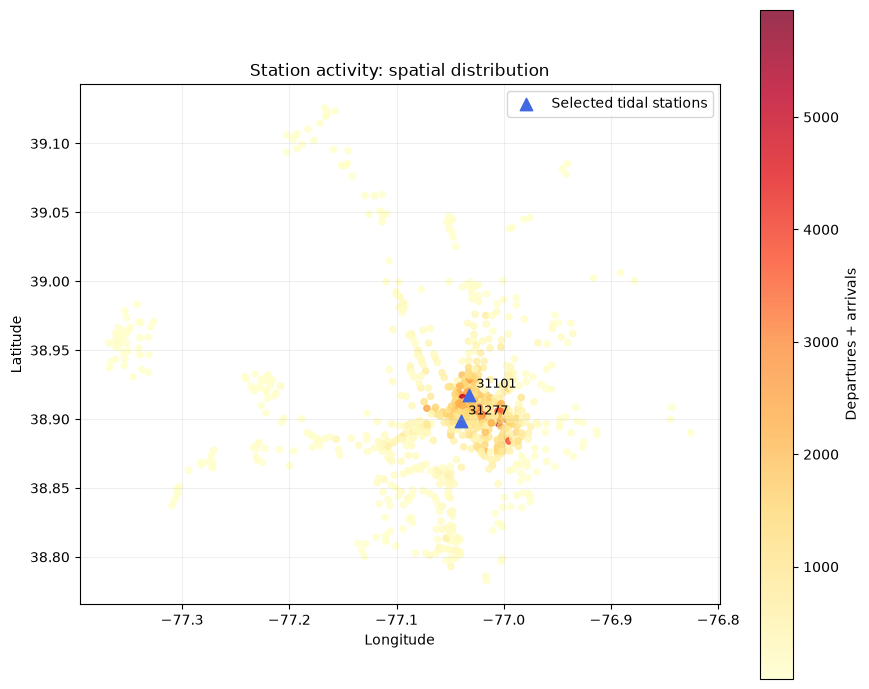

In [29]:
# 1. 将起点和终点的站点坐标整理成相同格式
start_coords = df_valid[
    ["start_station_id", "start_lat", "start_lng"]
].rename(columns={
    "start_station_id": "station_id",
    "start_lat": "latitude",
    "start_lng": "longitude"
})

end_coords = df_valid[
    ["end_station_id", "end_lat", "end_lng"]
].rename(columns={
    "end_station_id": "station_id",
    "end_lat": "latitude",
    "end_lng": "longitude"
})

coord_records = pd.concat(
    [start_coords, end_coords],
    ignore_index=True
).dropna(subset=["station_id", "latitude", "longitude"])

# 2. 检查经纬度取值范围
coord_records = coord_records.loc[
    coord_records["latitude"].between(-90, 90)
    & coord_records["longitude"].between(-180, 180)
]

# 同一个站点可能记录了略有差异的坐标，取中位数作为展示位置
station_coords = (
    coord_records.groupby("station_id")[
        ["latitude", "longitude"]
    ].median()
)

# 3. 将位置与之前的站点流量表连接
station_map = station_flow.join(station_coords)

print("站点总数：", len(station_map))
print(
    "缺少可用坐标的站点数：",
    station_map[["latitude", "longitude"]]
    .isna().any(axis=1).sum()
)

map_data = station_map.dropna(
    subset=["latitude", "longitude"]
)

# 4. 颜色表示借出与归还的总次数
fig, ax = plt.subplots(figsize=(9, 7))

points = ax.scatter(
    map_data["longitude"],
    map_data["latitude"],
    c=map_data["total_events"],
    s=20,
    cmap="YlOrRd",
    alpha=0.8
)

fig.colorbar(
    points,
    ax=ax,
    label="Departures + arrivals"
)

# 5. 标出两个重点案例
selected = map_data.loc[
    map_data.index.isin(["31277", "31101"])
]

ax.scatter(
    selected["longitude"],
    selected["latitude"],
    marker="^",
    s=80,
    color="royalblue",
    label="Selected tidal stations"
)

for station_id, row in selected.iterrows():
    ax.annotate(
        str(station_id),
        (row["longitude"], row["latitude"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# 对当地经纬度作近似比例调整
mean_latitude = map_data["latitude"].mean()
ax.set_aspect(1 / np.cos(np.deg2rad(mean_latitude)))

ax.set_title("Station activity: spatial distribution")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [30]:
# 1. 汇总整个 1 月的小时订单量
full_hours = pd.date_range(
    month_start,
    month_end,
    freq="h",
    inclusive="left"
)

hourly_demand = (
    df_valid.set_index("started_at")
    .resample("h")
    .size()
    .reindex(full_hours, fill_value=0)
    .rename("rides")
    .to_frame()
)
hourly_demand.index.name = "hour_start"

# 2. 添加预测时已经知道的日历信息
hourly_demand["hour"] = hourly_demand.index.hour
hourly_demand["weekday"] = hourly_demand.index.dayofweek
hourly_demand["is_weekend"] = (
    hourly_demand["weekday"] >= 5
).astype(int)

# 3. 添加历史订单量
hourly_demand["lag_1"] = hourly_demand["rides"].shift(1)
hourly_demand["lag_24"] = hourly_demand["rides"].shift(24)
hourly_demand["lag_168"] = hourly_demand["rides"].shift(168)

# 4. 过去 3 小时、24 小时的平均订单量
# 必须先 shift(1)，排除正在预测的这一小时
hourly_demand["mean_3"] = (
    hourly_demand["rides"].shift(1).rolling(3).mean()
)
hourly_demand["mean_24"] = (
    hourly_demand["rides"].shift(1).rolling(24).mean()
)

# 5. 明确输入特征，rides 是要预测的目标
feature_cols = [
    "hour", "weekday", "is_weekend",
    "lag_1", "lag_24", "lag_168",
    "mean_3", "mean_24"
]

# 最前面的小时没有足够历史，不能用于这一版本的模型
model_data = hourly_demand.dropna(
    subset=feature_cols + ["rides"]
).copy()

# 6. 按时间划分，不能随机打乱
train_set = model_data.loc[
    model_data.index < "2024-01-21"
].copy()

val_set = model_data.loc[
    (model_data.index >= "2024-01-21")
    & (model_data.index < "2024-01-26")
].copy()

test_set = model_data.loc[
    model_data.index >= "2024-01-26"
].copy()

print("原始小时数：", len(hourly_demand))
print("可用于建模的小时数：", len(model_data))
print("训练集：", len(train_set))
print("验证集：", len(val_set))
print("测试集：", len(test_set))

display(
    model_data[
        ["rides", "lag_1", "lag_24", "lag_168", "mean_24"]
    ].head()
)

原始小时数： 744
可用于建模的小时数： 576
训练集： 312
验证集： 120
测试集： 144


,rides,lag_1,lag_24,lag_168,mean_24
hour_start,,,,,
2024-01-08 00:00:00,47,116.0,116.0,272.0,343.916667
2024-01-08 01:00:00,28,47.0,96.0,324.0,341.041667
2024-01-08 02:00:00,14,28.0,64.0,237.0,338.208333
2024-01-08 03:00:00,10,14.0,32.0,60.0,336.125000
2024-01-08 04:00:00,20,10.0,19.0,26.0,335.208333


验证集基线结果：


,MAE,RMSE
Previous day,74.46,121.90
Previous hour,113.45,166.33
Previous week,173.70,246.73


验证集 MAE 最低的基线： Previous day


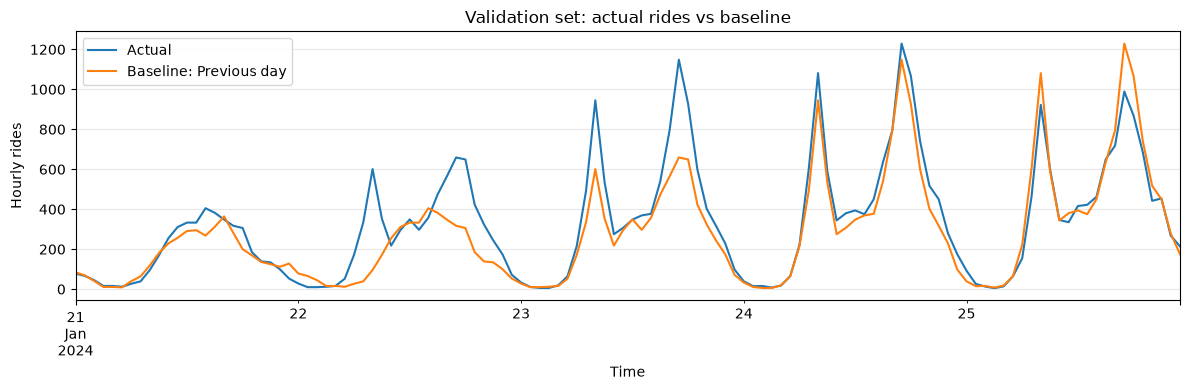

In [31]:
# 1. 定义评价函数
def evaluate_forecast(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    error = y_true - y_pred

    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt((error ** 2).mean())
    }

# 2. 三种基线在验证集上的预测
baseline_val_predictions = pd.DataFrame({
    "Previous hour": val_set["lag_1"],
    "Previous day": val_set["lag_24"],
    "Previous week": val_set["lag_168"]
})

# 3. 分别计算误差
baseline_scores = pd.DataFrame({
    name: evaluate_forecast(
        val_set["rides"],
        baseline_val_predictions[name]
    )
    for name in baseline_val_predictions.columns
}).T.sort_values("MAE")

print("验证集基线结果：")
display(baseline_scores.round(2))

# 4. 按验证集 MAE 选择表现最好的基线
best_baseline = baseline_scores.index[0]
print("验证集 MAE 最低的基线：", best_baseline)

# 5. 对比实际订单量与该基线的预测
val_plot = pd.DataFrame({
    "Actual": val_set["rides"],
    f"Baseline: {best_baseline}":
        baseline_val_predictions[best_baseline]
})

ax = val_plot.plot(figsize=(12, 4))

ax.set_title("Validation set: actual rides vs baseline")
ax.set_xlabel("Time")
ax.set_ylabel("Hourly rides")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

验证集方法对比：


,MAE,RMSE
Random forest,64.63,101.18
Previous day,74.46,121.90
Previous hour,113.45,166.33
Previous week,173.70,246.73


相对最佳基线，MAE 降低：13.20%
正数表示改善，负数表示误差变大。


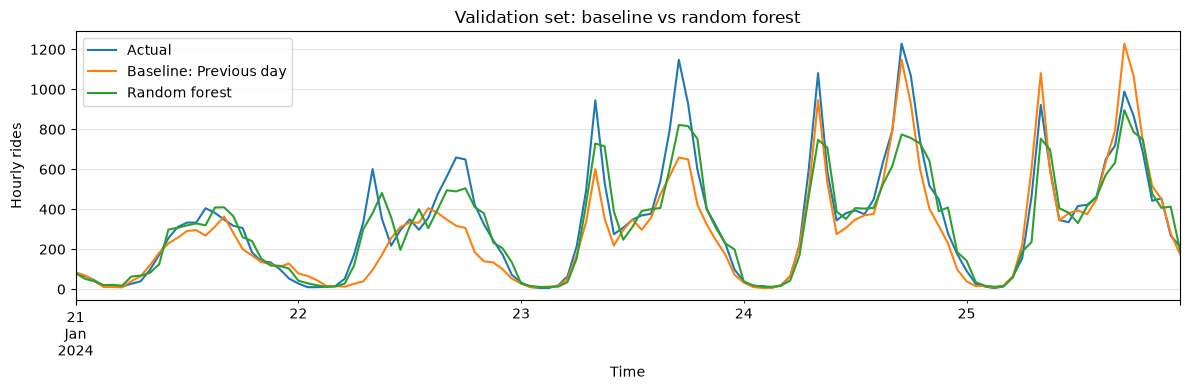

In [36]:
from sklearn.ensemble import RandomForestRegressor

# 1. 准备输入特征 X 和预测目标 y
X_train = train_set[feature_cols]
y_train = train_set["rides"]

X_val = val_set[feature_cols]
y_val = val_set["rides"]

# 2. 建立模型
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# 3. 只用训练集学习
rf_model.fit(X_train, y_train)

# 4. 在验证集上预测
rf_val_predictions = pd.Series(
    rf_model.predict(X_val),
    index=val_set.index,
    name="Random forest"
)

# 5. 使用与基线完全相同的指标评价
rf_val_metrics = evaluate_forecast(
    y_val,
    rf_val_predictions
)

rf_score_row = pd.DataFrame(
    [rf_val_metrics],
    index=["Random forest"]
)

model_val_scores = pd.concat(
    [baseline_scores, rf_score_row]
).sort_values("MAE")

print("验证集方法对比：")
display(model_val_scores.round(2))

# 6. 计算相对最佳基线的误差变化
baseline_mae = baseline_scores.loc[best_baseline, "MAE"]

improvement_pct = (
    (baseline_mae - rf_val_metrics["MAE"])
    / baseline_mae
    * 100
)

print(
    f"相对最佳基线，MAE 降低：{improvement_pct:.2f}%"
)
print("正数表示改善，负数表示误差变大。")

# 7. 对比实际值、最佳基线和随机森林
comparison_plot = pd.DataFrame({
    "Actual": y_val,
    f"Baseline: {best_baseline}":
        baseline_val_predictions[best_baseline],
    "Random forest": rf_val_predictions
})

ax = comparison_plot.plot(
    figsize=(12, 4),
    linewidth=1.5
)

ax.set_title("Validation set: baseline vs random forest")
ax.set_xlabel("Time")
ax.set_ylabel("Hourly rides")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

最终训练小时数： 432
最终测试小时数： 144

最终测试集结果：


,MAE,RMSE
Previous day,158.29,239.46
Random forest,94.88,147.72


测试集上，随机森林的 MAE 相对基线降低：40.06%
正数表示改善，负数表示误差变大。


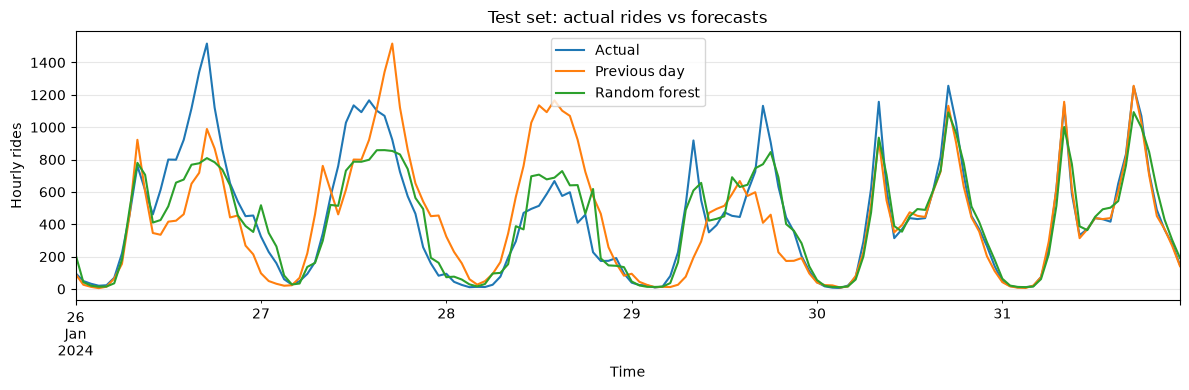

In [37]:
from sklearn.base import clone

# 1. 合并训练集和验证集
refit_data = pd.concat(
    [train_set, val_set]
).sort_index()

# 2. 复制相同的模型参数，重新训练
# clone 不会复制之前学到的结果
final_model = clone(rf_model)

final_model.fit(
    refit_data[feature_cols],
    refit_data["rides"]
)

print("最终训练小时数：", len(refit_data))
print("最终测试小时数：", len(test_set))

# 3. 生成测试集预测
test_predictions = pd.DataFrame({
    "Actual": test_set["rides"],
    "Previous day": test_set["lag_24"],
    "Random forest": final_model.predict(
        test_set[feature_cols]
    )
}, index=test_set.index)

# 4. 比较测试集误差
test_scores = pd.DataFrame({
    name: evaluate_forecast(
        test_predictions["Actual"],
        test_predictions[name]
    )
    for name in ["Previous day", "Random forest"]
}).T

print("\n最终测试集结果：")
display(test_scores.round(2))

# 5. 计算随机森林相对基线的改善比例
test_improvement_pct = (
    (
        test_scores.loc["Previous day", "MAE"]
        - test_scores.loc["Random forest", "MAE"]
    )
    / test_scores.loc["Previous day", "MAE"]
    * 100
)

print(
    f"测试集上，随机森林的 MAE 相对基线降低："
    f"{test_improvement_pct:.2f}%"
)
print("正数表示改善，负数表示误差变大。")

# 6. 绘制最终预测效果
ax = test_predictions.plot(
    figsize=(12, 4),
    linewidth=1.5
)

ax.set_title("Test set: actual rides vs forecasts")
ax.set_xlabel("Time")
ax.set_ylabel("Hourly rides")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

固定模型参数并合并训练集与验证集重新训练后，以 1 月 26–31 日作为测试期，进行逐小时滚动的一步预测。随机森林的 MAE 为 94.88、RMSE 为 147.72，相较“前一天同小时”基线，MAE 降低了 40.06%。模型能够较好地跟随日内需求变化，但对部分突出的需求峰值仍存在低估。该结果反映本次测试期的表现，尚需更长时间的数据检验。

In [38]:
# 1. 逐小时计算误差
error_detail = test_predictions.copy()

# 有符号误差：预测值 - 实际值
# 正数表示高估，负数表示低估
error_detail["rf_error"] = (
    error_detail["Random forest"] - error_detail["Actual"]
)

error_detail["rf_abs_error"] = error_detail["rf_error"].abs()

error_detail["baseline_abs_error"] = (
    error_detail["Previous day"] - error_detail["Actual"]
).abs()

# 2. 沿用之前的日期和时段划分
error_detail["day_type"] = np.where(
    error_detail.index.dayofweek < 5,
    "Mon-Fri",
    "Sat-Sun"
)

hours = error_detail.index.hour

error_detail["period"] = np.select(
    [
        (hours >= 7) & (hours < 10),
        (hours >= 16) & (hours < 19)
    ],
    ["AM peak", "PM peak"],
    default="Other hours"
)

# 3. 比较各类时段的误差
error_by_period = (
    error_detail
    .groupby(["day_type", "period"])
    .agg(
        n_hours=("Actual", "size"),
        mean_actual=("Actual", "mean"),
        RF_MAE=("rf_abs_error", "mean"),
        baseline_MAE=("baseline_abs_error", "mean"),
        RF_bias=("rf_error", "mean")
    )
)

print("分时段误差：")
display(error_by_period.round(2))

# 4. 找出随机森林误差最大的 5 个小时
print("随机森林误差最大的 5 个小时：")

display(
    error_detail.nlargest(5, "rf_abs_error")[
        [
            "Actual",
            "Previous day",
            "Random forest",
            "rf_error",
            "rf_abs_error"
        ]
    ].round(2)
)

分时段误差：


n_hours  mean_actual  RF_MAE  baseline_MAE  RF_bias
day_type period                                                          
Mon-Fri  AM peak           12       714.17  124.22        171.42   -35.99
         Other hours       72       320.76   58.07         78.42    -3.59
         PM peak           12      1082.92  221.81        258.33  -218.29
Sat-Sun  AM peak            6       273.50   42.85        211.50    -3.71
         Other hours       36       365.39  122.26        228.03     9.89
         PM peak            6       697.17  111.76        418.83    17.85

随机森林误差最大的 5 个小时：


,Actual,Previous day,Random forest,rf_error,rf_abs_error
hour_start,,,,,
2024-01-26 17:00:00,1517,989.0,808.78,-708.22,708.22
2024-01-26 16:00:00,1341,718.0,776.88,-564.12,564.12
2024-01-28 19:00:00,227,573.0,618.09,391.09,391.09
2024-01-27 14:00:00,1166,922.0,798.66,-367.34,367.34
2024-01-29 17:00:00,1132,409.0,771.12,-360.88,360.88


In [39]:
from pathlib import Path

# 保存到 Notebook 当前工作目录下
result_dir = Path.cwd() / "project_results"
result_dir.mkdir(parents=True, exist_ok=True)

# 汇总站点证据和建议
dispatch_suggestions = top_tidal[
    ["station_name", "am_net_per_day", "pm_net_per_day"]
].join(
    stability[["both_match_days", "both_match_pct"]]
)

dispatch_suggestions["AM_focus"] = np.where(
    dispatch_suggestions["am_net_per_day"] > 0,
    "检查可用车辆，结合库存判断是否补车",
    "检查停车容量，结合库存判断是否疏解"
)

dispatch_suggestions["PM_focus"] = np.where(
    dispatch_suggestions["pm_net_per_day"] > 0,
    "检查可用车辆，结合库存判断是否补车",
    "检查停车容量，结合库存判断是否疏解"
)

# 导出关键结果表
result_tables = {
    "validation_scores": model_val_scores,
    "test_scores": test_scores,
    "test_predictions": test_predictions,
    "error_by_period": error_by_period,
    "station_flow": station_flow,
    "dispatch_suggestions": dispatch_suggestions
}

for name, table in result_tables.items():
    table.to_csv(
        result_dir / f"{name}.csv",
        encoding="utf-8-sig",
        index=True
    )

print("结果已保存到：", result_dir.resolve())
display(dispatch_suggestions.round(2))

结果已保存到： project_results


,station_name,am_net_per_day,pm_net_per_day,both_match_days,both_match_pct,AM_focus,PM_focus
station_id,,,,,,,
31242,18th St & Pennsylvania Ave NW,-13.61,10.78,20,86.96,检查停车容量，结合库存判断是否疏解,检查可用车辆，结合库存判断是否补车
31101,14th & V St NW,11.91,-9.35,20,86.96,检查可用车辆，结合库存判断是否补车,检查停车容量，结合库存判断是否疏解
31279,19th & G St NW,-11.09,8.96,19,82.61,检查停车容量，结合库存判断是否疏解,检查可用车辆，结合库存判断是否补车
31229,New Hampshire Ave & T St NW,11.48,-8.91,19,82.61,检查可用车辆，结合库存判断是否补车,检查停车容量，结合库存判断是否疏解
31277,17th & G St NW,-16.22,7.83,21,91.30,检查停车容量，结合库存判断是否疏解,检查可用车辆，结合库存判断是否补车
31125,15th & W St NW,8.83,-7.57,20,86.96,检查可用车辆，结合库存判断是否补车,检查停车容量，结合库存判断是否疏解
31272,Washington & Independence Ave SW/HHS,-7.43,7.57,20,86.96,检查停车容量，结合库存判断是否疏解,检查可用车辆，结合库存判断是否补车
31233,17th & K St NW / Farragut Square,-15.17,7.26,18,78.26,检查停车容量，结合库存判断是否疏解,检查可用车辆，结合库存判断是否补车
